# GBPUSD H4 feature engineering

Research note on whether simple bar features forecast the next 4-hour log return.
The sample is GBPUSD pulled from a logged-in MetaTrader 5 terminal: 5,000 H4 bars and the M30 bars underneath them.
Feature choices are made only on the first 70% of the sample. The last 30% is reported once, after the choice is fixed.

This is not a trading recommendation. A statistic estimated at the bar close is not a fill at that same close.

## 1. Data checks

The target later in this note is a return, so the bars have to be a single ordered UTC series with valid OHLC.
I check four things before any feature is calculated: timestamps parse as UTC, duplicate timestamps are removed, prices are positive, and `high` / `low` actually contain the open and the close.
The H4 file is the series I want to forecast. The M30 file is only there to time the high and the low inside each H4 bar.

In [1]:
%matplotlib inline
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.stats import spearmanr, pearsonr, rankdata, skew
from numpy.lib.stride_tricks import sliding_window_view
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent

def load_bars(path):
    df = pd.read_csv(path, parse_dates=["time"])
    df["time"] = pd.to_datetime(df["time"], utc=True)
    df = df.set_index("time").sort_index()
    duplicates = int(df.index.duplicated().sum())
    df = df[~df.index.duplicated(keep="last")]
    for col in ("open", "high", "low", "close"):
        df[col] = pd.to_numeric(df[col], errors="coerce")
    missing = df[["open", "high", "low", "close"]].isna().any(axis=1)
    positive = (df[["open", "high", "low", "close"]] > 0).all(axis=1)
    consistent = (df["high"] >= df[["open", "close", "low"]].max(axis=1)) & (
        df["low"] <= df[["open", "close", "high"]].min(axis=1)
    )
    bad = ~(missing.eq(False) & positive & consistent)
    report = {
        "rows": int(len(df)),
        "duplicates_removed": duplicates,
        "invalid_ohlc": int(bad.sum()),
        "start": str(df.index.min()),
        "end": str(df.index.max()),
    }
    if bad.any():
        raise ValueError(f"{path.name} has {bad.sum()} invalid OHLC rows")
    return df, report

h4, h4_report = load_bars(ROOT / "data" / "raw" / "GBPUSD_H4.csv")
m30, m30_report = load_bars(ROOT / "data" / "raw" / "GBPUSD_M30.csv")
print("H4 ", h4_report)
print("M30", m30_report)
print("M30 covers H4:", m30.index.min() <= h4.index.min() and m30.index.max() >= h4.index.max())

H4  {'rows': 5000, 'duplicates_removed': 0, 'invalid_ohlc': 0, 'start': '2023-07-24 04:00:00+00:00', 'end': '2026-10-09 16:00:00+00:00'}
M30 {'rows': 50000, 'duplicates_removed': 0, 'invalid_ohlc': 0, 'start': '2022-09-30 07:30:00+00:00', 'end': '2026-10-09 17:30:00+00:00'}
M30 covers H4: True


## 2. High and low timing

`HighLowTime` does not invent the high and the low. Those prices already sit on the H4 bar.
What it adds is the M30 timestamp of the highest high and the lowest low inside each completed H4 interval.
That order is known only after the H4 bar has closed, and it is unknown when both extremes fall inside the same M30 bar.
I keep those ambiguous rows out of the `high_first` feature. I do not treat them as a zero-profit trade, because this note is not simulating stops.

In [2]:
def find_timestamp_extremum(higher, lower):
    """M30 timestamp of the high and the low inside each completed H4 bar."""
    higher = higher.loc[lower.index.min():].copy()
    highs, lows = [], []
    index = higher.index
    for i in range(len(index) - 1):
        window = lower.loc[index[i]:index[i + 1]].iloc[:-1]
        if window.empty:
            highs.append(pd.NaT)
            lows.append(pd.NaT)
        else:
            highs.append(window["high"].idxmax())
            lows.append(window["low"].idxmin())
    out = higher.iloc[:-1].copy()
    out["high_time"] = pd.to_datetime(highs, utc=True)
    out["low_time"] = pd.to_datetime(lows, utc=True)
    return out

bars = find_timestamp_extremum(h4, m30)
missing_extreme = bars[["high_time", "low_time"]].isna().any(axis=1)
same_m30_bar = bars["high_time"].eq(bars["low_time"])
print(f"H4 bars with a completed next bar: {len(bars)}")
print(f"Missing an extreme: {missing_extreme.mean():.2%}")
print(f"High and low share one M30 bar: {same_m30_bar.mean():.2%}")
bars.to_csv(ROOT / "data" / "processed" / "GBPUSD_H4_READY.csv")

H4 bars with a completed next bar: 4999
Missing an extreme: 0.02%
High and low share one M30 bar: 2.52%


## 3. Feature construction

The forecast is a return, so the feature has to be something that can stay in a bounded range while the price level trends.
A raw SMA is a price. Its correlation with a return is not a usable signal, and I do not calculate one.
Each feature below is a distance, a return, a bounded oscillator, or a scale ratio. Every input is shifted or rolled so that bar `t` uses only information available at the close of bar `t`.

| Feature | What it measures | Warmup |
| --- | --- | --- |
| `dist_sma_20`, `dist_sma_50` | Close relative to its own moving average | 20, 50 bars |
| `sma_spread_20_50` | Gap between the 20- and 50-bar averages | 50 bars |
| `RSI_14` | Wilder RSI | 14 bars |
| `ret_1`, `ret_5`, `ret_20` | Trailing log return | 1, 5, 20 bars |
| `atr_pct_14` | Wilder ATR divided by price | 14 bars |
| `vol_20` | Standard deviation of 1-bar log returns | 21 bars |
| `vol_ratio_5_20` | Short volatility over 20-bar volatility | 20 bars |
| `parkinson_20` | Range-based volatility | 20 bars |
| `rs_vol_20` | Rogers-Satchell volatility | 20 bars |
| `filling`, `amplitude` | Body as a fraction of the range, and body as a fraction of price | current bar |
| `rel_volume_20` | Log tick-count relative to its 20-bar average | 20 bars |
| `skew_20`, `autocorr_20` | Skew and lag-1 autocorrelation of recent returns | 20 bars |
| `high_first` | 1 when the M30 high prints before the M30 low | completed bar; blank if ambiguous |

`tick_volume` on this broker is a tick count, not exchange volume. I still test it once, because activity is on the feature list, and then I expect to drop it if it does not forecast the return.

In [3]:
def add_features(df):
    out = df.copy()
    close = out["close"]
    log_close = np.log(close)
    log_return = log_close.diff()
    sma20 = close.rolling(20, min_periods=20).mean()
    sma50 = close.rolling(50, min_periods=50).mean()
    out["dist_sma_20"] = close / sma20 - 1
    out["dist_sma_50"] = close / sma50 - 1
    out["sma_spread_20_50"] = sma20 / sma50 - 1

    delta = close.diff()
    avg_gain = delta.clip(lower=0).ewm(alpha=1 / 14, adjust=False, min_periods=14).mean()
    avg_loss = (-delta.clip(upper=0)).ewm(alpha=1 / 14, adjust=False, min_periods=14).mean()
    out["RSI_14"] = 100 - 100 / (1 + avg_gain / avg_loss.replace(0, np.nan))
    out.loc[(avg_loss == 0) & (avg_gain > 0), "RSI_14"] = 100
    out.loc[(avg_gain == 0) & (avg_loss > 0), "RSI_14"] = 0

    for horizon in (1, 5, 20):
        out[f"ret_{horizon}"] = log_close - log_close.shift(horizon)

    previous = close.shift(1)
    true_range = pd.concat(
        [out["high"] - out["low"], (out["high"] - previous).abs(), (out["low"] - previous).abs()],
        axis=1,
    ).max(axis=1)
    out["atr_pct_14"] = true_range.ewm(alpha=1 / 14, adjust=False, min_periods=14).mean() / close
    out["vol_20"] = log_return.rolling(20, min_periods=20).std()
    out["vol_ratio_5_20"] = log_return.rolling(5, min_periods=5).std() / out["vol_20"]
    out["parkinson_20"] = np.sqrt((np.log(out["high"] / out["low"]) ** 2).rolling(20).mean() / (4 * np.log(2)))
    rs = np.log(out["high"] / close) * np.log(out["high"] / out["open"]) + np.log(out["low"] / close) * np.log(out["low"] / out["open"])
    out["rs_vol_20"] = np.sqrt(rs.clip(lower=0).rolling(20).mean())
    span = (out["high"] - out["low"]).replace(0, np.nan)
    out["filling"] = (close - out["open"]).abs() / span
    out["amplitude"] = (close - out["open"]).abs() / ((out["open"] + close) / 2)
    out["rel_volume_20"] = np.log(out["tick_volume"] / out["tick_volume"].rolling(20).mean())
    out["skew_20"] = log_return.rolling(20).skew()
    out["autocorr_20"] = log_return.rolling(20).corr(log_return.shift(1))
    out["high_first"] = np.where(out["high_time"] < out["low_time"], 1.0, 0.0)
    out.loc[out["high_time"].isna() | out["low_time"].isna() | out["high_time"].eq(out["low_time"]), "high_first"] = np.nan
    out["target"] = np.log(close.shift(-1) / close)
    return out

FEATURES = [
    "dist_sma_20", "dist_sma_50", "sma_spread_20_50", "RSI_14",
    "ret_1", "ret_5", "ret_20", "atr_pct_14", "vol_20", "vol_ratio_5_20",
    "parkinson_20", "rs_vol_20", "filling", "amplitude", "rel_volume_20",
    "skew_20", "autocorr_20", "high_first",
]
frame = add_features(bars).dropna(subset=FEATURES + ["target"]).copy()
print(f"Rows after warmup: {len(frame)}")
print(f"Sample: {frame.index.min()} -> {frame.index.max()}")

Rows after warmup: 4823
Sample: 2023-08-03 08:00:00+00:00 -> 2026-10-09 08:00:00+00:00


## 4. Target and the research cut

The research target is the next H4 log return,

`r(t, 1) = ln(P(t+1) / P(t))`.

It is used only to score features. It is not a column I would hand to a live model.

The first 70% of the usable bars is the research sample. I drop the last research row as well, because its target is the first return of the holdout. All screening below uses the research sample only.

In [4]:
split = int(len(frame) * 0.7)
research = frame.iloc[:split - 1].copy()
holdout = frame.iloc[split:].copy()
print(f"Research: {len(research)} bars, {research.index.min()} -> {research.index.max()}")
print(f"Holdout:  {len(holdout)} bars, {holdout.index.min()} -> {holdout.index.max()}")

Research: 3375 bars, 2023-08-03 08:00:00+00:00 -> 2025-10-23 16:00:00+00:00
Holdout:  1447 bars, 2025-10-24 00:00:00+00:00 -> 2026-10-09 08:00:00+00:00


## 5. Predictive power of each feature

For each feature I calculate four related numbers on the research sample.

Spearman IC is the rank correlation with the next log return. I use ranks because the relationship does not have to be a straight line, and because a few large GBPUSD bars would otherwise dominate Pearson correlation. Pearson is reported next to it as the linear control. A rolling Spearman IC uses a 252-bar window, which is about six weeks of H4 trading, and is recomputed with ranks inside every window. The information ratio is the mean of that rolling IC divided by its standard deviation. Sign consistency is the share of windows whose IC has the same sign as the average.

A feature continues to the correlation step only when all of the following are true: absolute IC at least 0.03, absolute IR at least 0.5, rolling IC the same sign as the full-sample IC, and sign consistency at least 70%. These cuts are a filter for "worth comparing with the other survivors." They are not evidence that a feature is tradable. Eighteen features were tried. A naive p-value of 0.05 is too easy to clear, and a Bonferroni bar of 0.05/18 is about 0.0028. None of the p-values below reach that bar.

In [5]:
def rolling_spearman(x, y, window):
    paired = pd.concat([x, y], axis=1).dropna()
    out = pd.Series(np.nan, index=x.index)
    if len(paired) < window:
        return out
    left = sliding_window_view(paired.iloc[:, 0].to_numpy(dtype=float), window)
    right = sliding_window_view(paired.iloc[:, 1].to_numpy(dtype=float), window)
    left = rankdata(left, axis=1)
    right = rankdata(right, axis=1)
    left = left - left.mean(axis=1, keepdims=True)
    right = right - right.mean(axis=1, keepdims=True)
    denom = np.sqrt((left ** 2).sum(axis=1) * (right ** 2).sum(axis=1))
    with np.errstate(invalid="ignore", divide="ignore"):
        corr = (left * right).sum(axis=1) / denom
    out.loc[paired.index[window - 1:]] = corr
    return out

def screen_reason(row):
    reasons = []
    if abs(row["IC"]) < 0.03:
        reasons.append("|IC| < 0.03")
    if abs(row["IC_IR"]) < 0.5:
        reasons.append("|IR| < 0.5")
    if np.sign(row["IC"]) != np.sign(row["mean_IC"]):
        reasons.append("rolling sign disagrees")
    if row["sign_consistency"] < 0.70:
        reasons.append("sign consistency < 70%")
    return "keep for correlation" if not reasons else "; ".join(reasons)

rows = []
curves = {}
for name in FEATURES:
    pair = research[[name, "target"]].dropna()
    ic, p_s = spearmanr(pair[name], pair["target"])
    linear, p_p = pearsonr(pair[name], pair["target"])
    curve = rolling_spearman(research[name], research["target"], 252).dropna()
    curves[name] = curve
    mean_ic, std_ic = float(curve.mean()), float(curve.std())
    values = research[name].dropna()
    z = ((values - values.mean()) / values.std()).abs()
    rows.append({
        "feature": name,
        "IC": ic,
        "p_spearman": p_s,
        "pearson": linear,
        "p_pearson": p_p,
        "mean_IC": mean_ic,
        "IC_IR": mean_ic / std_ic,
        "sign_consistency": float((np.sign(curve) == np.sign(mean_ic)).mean()),
        "outlier_pct": float((z > 3).mean() * 100),
        "skew": float(skew(values)),
    })

report = pd.DataFrame(rows).set_index("feature")
report["decision"] = report.apply(screen_reason, axis=1)
report = report.sort_values("IC", key=np.abs, ascending=False)
kept = report.index[report["decision"].eq("keep for correlation")].tolist()
print(f"Kept for the correlation step: {kept}")
report.round(4)

Kept for the correlation step: ['dist_sma_20', 'RSI_14']


,IC,p_spearman,pearson,p_pearson,mean_IC,IC_IR,sign_consistency,outlier_pct,skew,decision
feature,,,,,,,,,,
dist_sma_20,-0.0369,0.0321,-0.0272,0.1136,-0.0524,-0.8354,0.7647,0.8000,0.0544,keep for correlation
ret_5,-0.0310,0.0717,-0.0175,0.3085,-0.0315,-0.5156,0.6258,0.8889,-0.0036,sign consistency < 70%
RSI_14,-0.0304,0.0777,-0.0231,0.1800,-0.0528,-0.8636,0.7891,0.0000,0.1121,keep for correlation
filling,-0.0289,0.0931,-0.0402,0.0194,-0.0290,-0.4523,0.7090,0.0000,0.0641,|IC| < 0.03; |IR| < 0.5
ret_1,-0.0269,0.1182,-0.0220,0.2012,-0.0223,-0.3741,0.6937,1.6296,-0.1354,|IC| < 0.03; |IR| < 0.5; sign consistency < 70%
rs_vol_20,0.0261,0.1295,0.0369,0.0322,0.0346,0.5920,0.6825,1.4222,1.1353,|IC| < 0.03; sign consistency < 70%
amplitude,-0.0259,0.1318,-0.0266,0.1230,-0.0284,-0.5433,0.6789,1.9556,2.1924,|IC| < 0.03; sign consistency < 70%
dist_sma_50,-0.0247,0.1507,-0.0232,0.1784,-0.0503,-0.8992,0.8035,0.2370,0.1582,|IC| < 0.03
ret_20,-0.0239,0.1644,-0.0226,0.1901,-0.0409,-0.6992,0.7538,0.8296,0.0889,|IC| < 0.03


## 6. What the individual tests say

The whole table is small. The largest Spearman IC on the research sample is about -0.037. That is a weak rank association, not a forecast I would trade. The signs that do show up are mostly negative: a bar that has already risen tends to be followed by a slightly lower next bar. That is short-horizon mean reversion, and several of the trend features are just different rulers for the same move.

**Distance to the 20-bar average** is the strongest row. Research IC is -0.0369, the naive Spearman p-value is 0.032, rolling IR is -0.84, and about 76% of the 252-bar windows have a negative IC. Pearson is weaker (-0.027, p=0.11), so the relationship is easier to see in ranks than in a straight line. It passes the filter. It still fails a multiple-testing correction, and the holdout check is below.

**RSI(14)** passes the same filter by a smaller margin: IC -0.0304, p=0.078, IR -0.86, sign consistency 79%. An RSI of 70 and a close sitting 0.3% above its 20-bar average are the same statement on this series. I keep it only long enough to measure that overlap.

**Five-bar return** has IC -0.031 and IR -0.52, but the sign is negative in only 63% of windows. The average is being pulled by part of the sample. I drop it before the correlation step.

**Fifty-bar distance and the 20-bar return** have stable negative rolling IC, but the full-sample IC is -0.025 and -0.024. Both are slower versions of the same extension. They do not clear the individual bar, so they do not go forward. The 20/50 average spread is weaker still (IC -0.006). The slope between two averages is not carrying the association; the distance of price from the faster average is.

**One-bar return** has IC -0.027, IR -0.37, and a naive p-value of 0.12. One lag of the return is too noisy to forecast the next lag here.

**Candle body.** `filling` and `amplitude` have IC near -0.027. Their rolling IR is around -0.5 and the sign is not stable enough. A large body says the current bar was directional. It does not say the next bar will be. Both also have a long right tail (`amplitude` skew is about 2.2), which is another reason not to treat the Pearson number as the main evidence. I drop both.

**Volatility levels do not forecast the next return.** `vol_20` has an IC of -0.004 and a rolling IC that is positive about as often as it is negative. ATR% and Parkinson volatility are the same kind of object: they describe how wide recent bars were. Width is useful for a stop. It is not a sign for the next return. Rogers-Satchell is the least weak of this group (IC +0.026, IR 0.59), but a quarter of the windows disagree on the sign and the naive p-value is 0.13. A positive IC here would mean "wider recent ranges, slightly higher next return," which is not a stable GBPUSD fact in this sample. The 5-bar/20-bar volatility ratio is also flat (IC -0.020, p=0.25). I drop the whole volatility group. They are also redundant with each other: ATR, Parkinson, close-to-close vol, and Rogers-Satchell have Spearman correlations from about 0.80 to 0.93. Keeping one of them would not create a second idea, and none of them earned the seat.

**Tick activity, skew, and autocorrelation** are flat. Relative tick volume has IC -0.017 (p=0.31). Rolling skew has IC about zero. Rolling lag-1 autocorrelation has IC -0.006 and an IR of -0.11. There is no reason to keep a feature whose rolling correlation changes sign on every other window.

**`high_first` has no forecast value.** Its IC with the next return is -0.006 (p=0.73). It is also not an independent description of the market: its correlation with the current bar's own return is about -0.76, because a bar that prints the high before the low usually closed lower. On top of that, 2.5% of H4 bars have the high and the low inside one M30 bar, so the order is unknowable. I drop it. The column stays in the prepared file because the timing itself was the preprocessing step; it is just not a feature I would select.

## 7. Do the survivors say the same thing?

The individual filter leaves `dist_sma_20` and `RSI_14`. Both say "price has already moved, and the next bar leans the other way." If their rank correlation is extreme, the one with the smaller correlation to the forward log return is the one to remove.

Spearman correlation of the features that passed the individual filter


,dist_sma_20,RSI_14
dist_sma_20,1.000,0.936
RSI_14,0.936,1.000


Selected: ['dist_sma_20']
Dropped as redundant: {'RSI_14': 'dist_sma_20'}


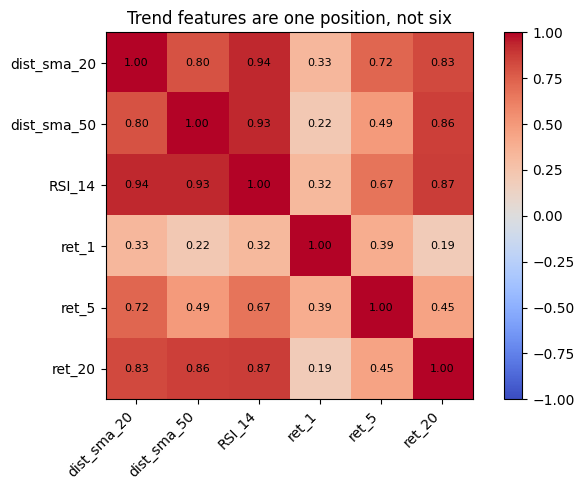

In [6]:
survivors = kept
corr = research[survivors].corr(method="spearman")
print("Spearman correlation of the features that passed the individual filter")
display(corr.round(3))

ic_abs = report.loc[survivors, "IC"].abs().sort_values(ascending=False)
selected, dropped = [], {}
for feature in ic_abs.index:
    clash = [name for name in selected if abs(corr.loc[feature, name]) >= 0.70]
    if clash:
        dropped[feature] = clash[0]
    else:
        selected.append(feature)
print("Selected:", selected)
print("Dropped as redundant:", dropped)

family = ["dist_sma_20", "dist_sma_50", "RSI_14", "ret_1", "ret_5", "ret_20"]
family_corr = research[family].corr(method="spearman")
fig, ax = plt.subplots(figsize=(7, 5))
image = ax.imshow(family_corr, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(family)), family, rotation=45, ha="right")
ax.set_yticks(range(len(family)), family)
for i in range(len(family)):
    for j in range(len(family)):
        ax.text(j, i, f"{family_corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(image, ax=ax)
ax.set_title("Trend features are one position, not six")
fig.tight_layout()

`dist_sma_20` and `RSI_14` have a Spearman correlation of 0.936. RSI has the smaller absolute IC against the next log return (-0.030 versus -0.037), so I drop RSI and keep the distance.

The heatmap is the same point made on the features that did not all pass the individual filter. Distance to the 20-bar average, distance to the 50-bar average, RSI, and the 20-bar return sit between 0.80 and 0.94. Adding a second one would double-count a single mean-reversion measurement.

The rolling IC of the retained feature is negative for most of the research sample, but it is not a straight line. The red line is the research-sample mean.

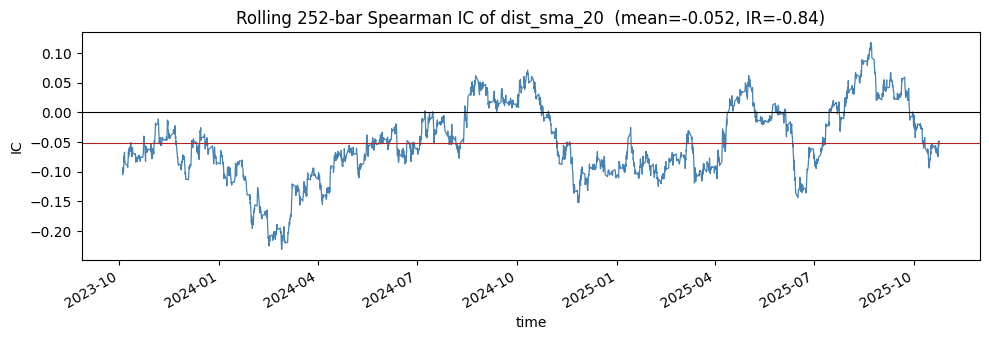

In [7]:
curve = curves["dist_sma_20"]
fig, ax = plt.subplots(figsize=(10, 3.5))
curve.plot(ax=ax, linewidth=0.9, color="steelblue")
ax.axhline(0, color="black", linewidth=0.8)
ax.axhline(curve.mean(), color="firebrick", linewidth=0.8)
ax.set_title(f"Rolling 252-bar Spearman IC of dist_sma_20  (mean={curve.mean():.3f}, IR={curve.mean() / curve.std():.2f})")
ax.set_ylabel("IC")
fig.tight_layout()

## 8. The feature does not mean the same thing in every regime

I split the research sample at the median of `vol_20` and recompute the IC of `dist_sma_20`. This split is descriptive. It is not a new feature search.

In [8]:
median_vol = research["vol_20"].median()
for label, part in (
    ("low volatility", research[research["vol_20"] <= median_vol]),
    ("high volatility", research[research["vol_20"] > median_vol]),
):
    ic, pvalue = spearmanr(part["dist_sma_20"], part["target"])
    print(f"{label:16} n={len(part):4d}  IC={ic:+.4f}  naive p={pvalue:.4f}")

low volatility   n=1688  IC=-0.0128  naive p=0.6000
high volatility  n=1687  IC=-0.0547  naive p=0.0246


The negative association is concentrated in the high-volatility half (IC -0.055, naive p=0.025). In the quiet half it is -0.013 with a p-value of 0.60. A feature that disappears when ranges are tight is not a stable description of GBPUSD. I would not promote it to a model on the back of the pooled IC alone.

## 9. Holdout, after the choice was fixed

The holdout was not used to pick the feature. It is one check that the research IC was not only a sample accident. With about 1,450 bars, an IC of -0.04 is still well inside sampling noise.

In [9]:
for label, part in (("research", research), ("holdout", holdout)):
    ic, pvalue = spearmanr(part["dist_sma_20"], part["target"])
    print(f"{label:10} n={len(part):4d}  IC={ic:+.4f}  naive p={pvalue:.4f}")

research   n=3375  IC=-0.0369  naive p=0.0321
holdout    n=1447  IC=-0.0386  naive p=0.1426


## 10. Conclusion

I keep one feature: **`dist_sma_20`**, the close divided by its 20-bar average, minus one.

Everything else is out.

- Volatility, tick activity, skew, autocorrelation, candle shape, the average-to-average spread, and `high_first` do not have a meaningful association with the next H4 log return. Volatility features are also copies of one another.
- The other trend features are copies of `dist_sma_20`. RSI is the only one that also passed the individual filter, and its correlation with the distance is 0.94, so it goes too.

What I will not claim: that this feature has predictive power in the sense a portfolio needs. The research IC is -0.037. The holdout point estimate is about -0.039, and its naive p-value is about 0.14. The relationship is mostly a high-volatility result. Eighteen tests were run, the p-values ignore overlapping returns and serial dependence, and nothing survives a multiple-testing correction. The prepared H4 file with high and low timestamps is `data/processed/GBPUSD_H4_READY.csv`.